Upload your Kaggle CSV dataset.


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv

Dataset loaded successfully!
Original dataset shape: (7043, 21)

Cleaned dataset shape: (7043, 20)

Missing values: 0

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


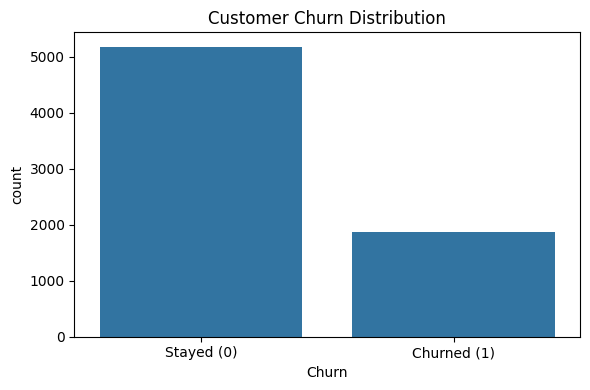

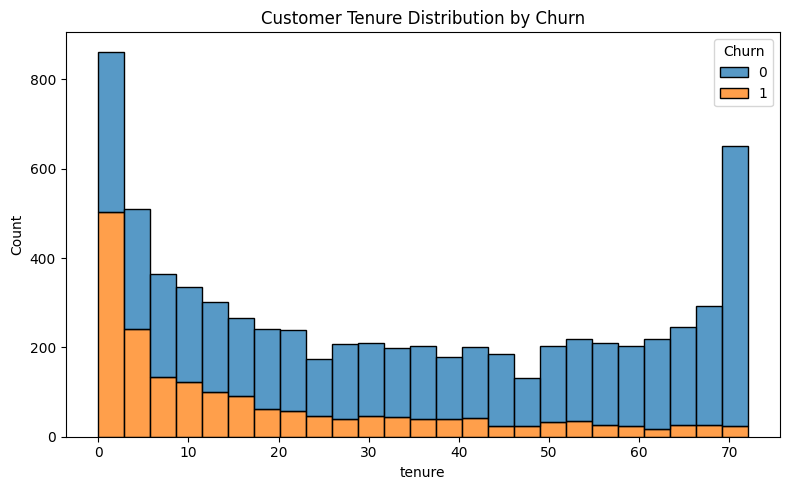


       XGBOOST MODEL EVALUATION
Accuracy Score: 0.8055 (80.55%)
RMSE:           0.3680

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.84      0.91      0.87      1035
     Churned       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



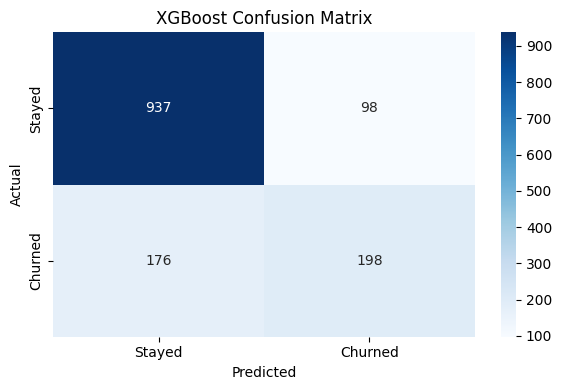

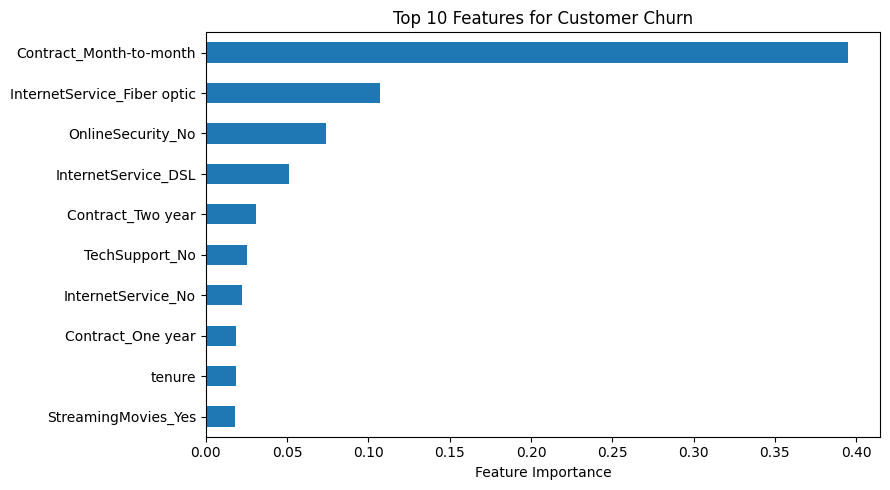


      PREDICT CHURN FOR A NEW CUSTOMER
Enter customer details below, then click Predict.


Button(button_style='primary', description='Predict Customer Churn', icon='check', style=ButtonStyle())

Output()


Project ready! Change the input fields and click Predict.


In [2]:

# ============================================================
# CUSTOMER CHURN PREDICTION - XGBOOST
# Google Colab | Complete single-cell project
# ============================================================

!pip -q install xgboost ipywidgets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from IPython.display import display, clear_output
from google.colab import files
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    classification_report,
    confusion_matrix
)

# 1. UPLOAD DATASET
print("Upload your Kaggle CSV dataset.")
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("Original dataset shape:", df.shape)

# 2. DATA CLEANING
df.columns = df.columns.str.strip()

if "Churn" not in df.columns:
    raise ValueError(
        "Target column 'Churn' was not found. "
        "Please upload the IBM Telco Customer Churn CSV."
    )

df = df.drop_duplicates()

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Convert TotalCharges to numeric if present
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

    # Blank charges commonly correspond to zero-tenure customers
    if "tenure" in df.columns:
        df.loc[
            df["TotalCharges"].isna() & (df["tenure"] == 0),
            "TotalCharges"
        ] = 0

# Normalize target
df["Churn"] = df["Churn"].astype(str).str.strip().str.title()
df = df[df["Churn"].isin(["Yes", "No"])].copy()
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Remove remaining rows with missing values
df = df.dropna().reset_index(drop=True)

if len(df) < 10:
    raise ValueError("Not enough valid rows to train a model.")

print("\nCleaned dataset shape:", df.shape)
print("\nMissing values:", int(df.isnull().sum().sum()))
print("\nTarget distribution:")
print(df["Churn"].value_counts())

# 3. EXPLORATORY DATA ANALYSIS
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xticks([0, 1], ["Stayed (0)", "Churned (1)"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tenure", hue="Churn",
             bins=25, multiple="stack")
plt.title("Customer Tenure Distribution by Churn")
plt.tight_layout()
plt.show()

# 4. PREPARE FEATURES AND TARGET
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

# Save original feature definitions for new customer inputs
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

# One-hot encode categorical features
X = pd.get_dummies(X, columns=categorical_cols, dtype=int)

# Keep the feature names used during training
feature_columns = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. TRAIN XGBOOST CLASSIFIER
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

# 6. EVALUATE MODEL
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_prob))

print("\n" + "=" * 45)
print("       XGBOOST MODEL EVALUATION")
print("=" * 45)
print(f"Accuracy Score: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"RMSE:           {rmse:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

# 7. CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. FEATURE IMPORTANCE
importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Features for Customer Churn")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

# 9. INTERACTIVE CUSTOMER PREDICTION
# Create an example customer using typical dataset values.
# Widgets let you change the values before predicting.

print("\n" + "=" * 45)
print("      PREDICT CHURN FOR A NEW CUSTOMER")
print("=" * 45)
print("Enter customer details below, then click Predict.")

# Build input defaults from the cleaned original data
raw_X = df.drop(columns=["Churn"]).copy()

# Customer ID was already removed during cleaning.
# Determine defaults from the available feature columns.
defaults = {}
for col in raw_X.columns:
    if col in numerical_cols:
        defaults[col] = float(raw_X[col].median())
    else:
        defaults[col] = raw_X[col].mode().iloc[0]

# Create widgets for each raw feature
input_widgets = {}

for col in raw_X.columns:
    if col in numerical_cols:
        minimum = float(raw_X[col].min())
        maximum = float(raw_X[col].max())
        default = float(defaults[col])

        input_widgets[col] = widgets.FloatSlider(
            value=default,
            min=minimum,
            max=maximum if maximum > minimum else minimum + 1,
            step=1 if raw_X[col].dtype.kind in "iu" else 0.5,
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="500px")
        )
    else:
        options = sorted(raw_X[col].astype(str).unique().tolist())
        default = str(defaults[col])

        input_widgets[col] = widgets.Dropdown(
            options=options,
            value=default if default in options else options[0],
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="500px")
        )

predict_button = widgets.Button(
    description="Predict Customer Churn",
    button_style="primary",
    icon="check"
)

output = widgets.Output()

def predict_customer(_):
    with output:
        clear_output()

        customer = pd.DataFrame([{
            col: widget.value
            for col, widget in input_widgets.items()
        }])

        # Encode the new customer exactly like training data
        customer = pd.get_dummies(
            customer,
            columns=categorical_cols,
            dtype=int
        )

        customer = customer.reindex(
            columns=feature_columns,
            fill_value=0
        )

        probability = model.predict_proba(customer)[0, 1]
        prediction = int(probability >= 0.5)

        print("PREDICTION RESULT")
        print("-" * 35)

        if prediction == 1:
            print("Prediction: WILL CHURN")
        else:
            print("Prediction: WILL STAY")

        print(f"Churn probability: {probability:.2%}")

        if prediction == 1:
            print("Suggested action: Consider customer retention measures.")
        else:
            print("Suggested action: Continue monitoring customer satisfaction.")

predict_button.on_click(predict_customer)

display(widgets.VBox(list(input_widgets.values())))
display(predict_button, output)

print("\nProject ready! Change the input fields and click Predict.")
